# Lab 26.2: A Readable Middle

Chapter 26, Casebook: Explainability Across Industries. Run every cell in order; no code needs to be written.

This notebook builds a small two-stage pipeline in the spirit of the retinal scan system of De Fauw et al. (2018): a **segmentation stage** turns a synthetic scan into a tissue map, and a **referral stage** reads only the tissue volumes. Then a second "device" changes how scans look. Everything is synthetic and runs in seconds. It is an analogy for the design idea, not a model of the real system.

In [1]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
import matplotlib.pyplot as plt

rng = np.random.default_rng(26)
SIZE = 32                       # scans are 32 x 32 pixels
TISSUES = ["retina", "fluid", "deposit"]
BASE = np.array([0.70, 0.30, 0.95])   # mean intensity of each tissue on device 1

def make_scan(device=1):
    """One synthetic scan: a label map (0 retina, 1 fluid, 2 deposit) and pixel intensities."""
    labels = np.zeros((SIZE, SIZE), int)
    yy, xx = np.mgrid[:SIZE, :SIZE]
    for _ in range(rng.integers(0, 4)):                 # fluid pockets
        cy, cx, r = rng.integers(4, 28), rng.integers(4, 28), rng.uniform(2, 6)
        labels[(yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2] = 1
    for _ in range(rng.integers(0, 3)):                 # bright deposits
        cy, cx, r = rng.integers(4, 28), rng.integers(4, 28), rng.uniform(1, 3)
        labels[(yy - cy) ** 2 + (xx - cx) ** 2 < r ** 2] = 2
    inten = BASE[labels] + rng.normal(0, 0.07, labels.shape)
    if device == 2:                                     # brighter, lower contrast, noisier
        inten = 0.45 + 0.9 * inten + rng.normal(0, 0.03, labels.shape)
    return labels, inten

def volumes(labels):
    return np.array([(labels == k).mean() for k in (1, 2)])   # fluid and deposit shares

def refer_truth(labels):
    f, d = volumes(labels)
    return int(f > 0.08 or d > 0.03)                    # the clinical rule the data follow

print("example volumes (fluid, deposit):", volumes(make_scan()[0]).round(3))

example volumes (fluid, deposit): [0.173 0.013]


## Step 1: train both stages on device 1

Stage 1 is a per-pixel classifier (gradient-boosted trees) on three features: the pixel's intensity, the mean of its 3 x 3 neighborhood and the median intensity of the whole scan. Stage 2 is a depth-2 decision tree on the two tissue volumes, so that you can read it as rules. The two stages are trained separately, as in the paper.

In [2]:
def pixel_features(inten):
    pad = np.pad(inten, 1, mode="edge")
    neigh = sum(pad[1 + dy:1 + dy + SIZE, 1 + dx:1 + dx + SIZE] for dy in (-1, 0, 1) for dx in (-1, 0, 1)) / 9
    return np.column_stack([inten.ravel(), neigh.ravel(), np.full(SIZE * SIZE, np.median(inten))])

def train_stage1(scans):
    X = np.vstack([pixel_features(i) for _, i in scans]); y = np.concatenate([l.ravel() for l, _ in scans])
    return HistGradientBoostingClassifier(max_iter=100, random_state=0).fit(X, y)

def segment(stage1, inten):
    return stage1.predict(pixel_features(inten)).reshape(SIZE, SIZE)

seg_train = [make_scan(1) for _ in range(20)]           # 20 scans with pixel labels
stage1 = train_stage1(seg_train)

cls_train = [make_scan(1) for _ in range(400)]          # 400 scans with referral labels only
Xv = np.array([volumes(segment(stage1, i)) for _, i in cls_train])
yv = np.array([refer_truth(l) for l, _ in cls_train])
stage2 = DecisionTreeClassifier(max_depth=2, random_state=0).fit(Xv, yv)
print(export_text(stage2, feature_names=["fluid_volume", "deposit_volume"]))

|--- fluid_volume <= 0.08
|   |--- deposit_volume <= 0.03
|   |   |--- class: 0
|   |--- deposit_volume >  0.03
|   |   |--- class: 1
|--- fluid_volume >  0.08
|   |--- class: 1



**Checkpoint 1.** Stage 2 prints as two rules: refer if fluid volume is above about 0.08, otherwise refer if deposit volume is above about 0.03. They recover the rule the synthetic data follow. Stage 2 never sees a pixel; it sees only the readable middle.

In [3]:
def evaluate(stage1, device, n=300):
    scans = [make_scan(device) for _ in range(n)]
    truth = np.array([refer_truth(l) for l, _ in scans])
    maps = [segment(stage1, i) for _, i in scans]
    pred = stage2.predict(np.array([volumes(m) for m in maps]))
    pix = np.mean([np.mean(m == l) for m, (l, _) in zip(maps, scans)])
    return np.mean(pred != truth), pix, scans, maps

err1, pix1, s1, m1 = evaluate(stage1, 1)
err2, pix2, s2, m2 = evaluate(stage1, 2)
print(f"device 1: referral error {err1:.1%}, pixel accuracy of tissue map {pix1:.1%}")
print(f"device 2: referral error {err2:.1%}, pixel accuracy of tissue map {pix2:.1%}")

device 1: referral error 1.0%, pixel accuracy of tissue map 99.8%
device 2: referral error 50.0%, pixel accuracy of tissue map 1.3%


**Checkpoint 2.** On device 1 the referral error is a few percent. On device 2 it jumps, and the pixel accuracy of the tissue map collapses with it. A clinician looking at the map, not only at the referral, would see what went wrong. Look:

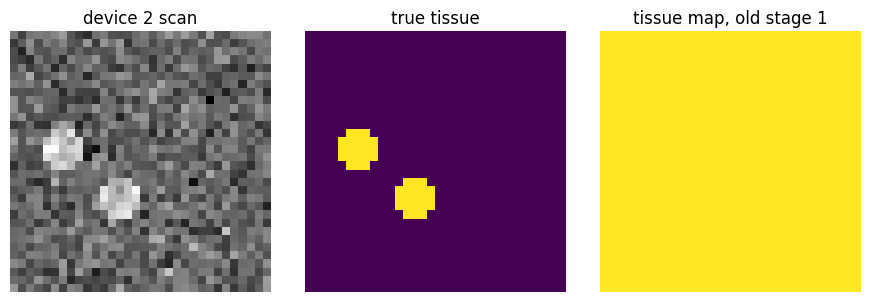

true volumes: [0.    0.041]  map volumes: [0. 1.]


In [4]:
k = int(np.argmax([refer_truth(l) for l, _ in s2]))   # first scan on device 2 that should be referred
fig, ax = plt.subplots(1, 3, figsize=(9, 3))
ax[0].imshow(s2[k][1], cmap="gray"); ax[0].set_title("device 2 scan")
ax[1].imshow(s2[k][0], vmin=0, vmax=2); ax[1].set_title("true tissue")
ax[2].imshow(m2[k], vmin=0, vmax=2); ax[2].set_title("tissue map, old stage 1")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("true volumes:", volumes(s2[k][0]).round(3), " map volumes:", volumes(m2[k]).round(3))

## Step 2: repair only stage 1

Label 10 scans from device 2, retrain stage 1 on both devices, and leave stage 2 exactly as it was.

In [5]:
seg_dev2 = [make_scan(2) for _ in range(10)]
stage1_new = train_stage1(seg_train + seg_dev2)
err2b, pix2b, _, _ = evaluate(stage1_new, 2)
err1b, pix1b, _, _ = evaluate(stage1_new, 1)
print(f"device 2 after refit: referral error {err2b:.1%}, pixel accuracy {pix2b:.1%}")
print(f"device 1 after refit: referral error {err1b:.1%}, pixel accuracy {pix1b:.1%}")

device 2 after refit: referral error 3.0%, pixel accuracy 99.3%
device 1 after refit: referral error 3.3%, pixel accuracy 99.5%


**Checkpoint 3.** The device 2 error falls back to the device 1 level, with stage 2 untouched, and device 1 still works.

## Step 3: what the middle does not tell you

The tissue map shows what stage 2 saw. Whether stage 2 weighs it the way a clinician would is a separate question. Here stage 2 is a two-level tree, so you can read it; in the real system the second stage is a deep network, and reading it needs the attribution methods of Part III.

In [6]:
print("Results table")
print(f"{'condition':38s} {'referral error':>15s} {'pixel accuracy':>15s}")
for name, e, p in [("device 1, stage 1 fit on device 1", err1, pix1),
                   ("device 2, same stage 1", err2, pix2),
                   ("device 2, stage 1 refit, stage 2 same", err2b, pix2b)]:
    print(f"{name:38s} {e:15.1%} {p:15.1%}")

Results table
condition                               referral error  pixel accuracy
device 1, stage 1 fit on device 1                 1.0%           99.8%
device 2, same stage 1                           50.0%            1.3%
device 2, stage 1 refit, stage 2 same             3.0%           99.3%


## Hand in

The results table and one paragraph: what can the tissue map tell a clinician about a referral, and what can it not tell them? Name the method from Part III you would use for the second question.